In [1]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
DATA_FILE = PROJECT_ROOT / "data" / "raw" / "abs_table17.xlsx"

print("项目根目录：", PROJECT_ROOT)
print("Excel路径：", DATA_FILE)
print("文件是否存在：", DATA_FILE.exists())

项目根目录： /Users/tttonya/PycharmProjects/JupyterProject
Excel路径： /Users/tttonya/PycharmProjects/JupyterProject/data/raw/abs_table17.xlsx
文件是否存在： True


In [5]:
from pathlib import Path
import pandas as pd

raw_file = Path("../data/raw/abs_table17.xlsx")

df = pd.read_excel(
    raw_file,
    sheet_name="Table 17",
    header=[5, 6]
)

df.columns = [
    "state_code", "state", "visa_group", "applicant_status",
    "industry", "sex",
    "jobs_2018_19", "jobs_2019_20", "jobs_2020_21",
    "jobs_2021_22", "jobs_2022_23",
    "income_2018_19", "income_2019_20", "income_2020_21",
    "income_2021_22", "income_2022_23"
]

# 删除表格底部的脚注
df = df[
    pd.to_numeric(df["state_code"], errors="coerce").notna()
].copy()

value_cols = [
    c for c in df.columns
    if c.startswith("jobs_") or c.startswith("income_")
]

# 保留数据质量信息
df["has_suppressed_value"] = (
    df[value_cols].astype(str).eq("np").any(axis=1)
)

df["has_nil_or_rounded_zero"] = (
    df[value_cols].astype(str).eq("-").any(axis=1)
)

# np是未公布，转成缺失值；“-”是nil或四舍五入为0
df[value_cols] = (
    df[value_cols]
    .replace({"np": pd.NA, "-": 0})
    .apply(pd.to_numeric, errors="coerce")
)

id_cols = [
    "state_code", "state", "visa_group",
    "applicant_status", "industry", "sex",
    "has_suppressed_value", "has_nil_or_rounded_zero"
]

jobs = df.melt(
    id_vars=id_cols,
    value_vars=[c for c in df.columns if c.startswith("jobs_")],
    var_name="year",
    value_name="jobs"
)

jobs["year"] = (
    jobs["year"]
    .str.replace("jobs_", "", regex=False)
    .str.replace("_", "-", regex=False)
)

income = df.melt(
    id_vars=id_cols,
    value_vars=[c for c in df.columns if c.startswith("income_")],
    var_name="year",
    value_name="median_income_per_job"
)

income["year"] = (
    income["year"]
    .str.replace("income_", "", regex=False)
    .str.replace("_", "-", regex=False)
)

panel = jobs.merge(
    income,
    on=id_cols + ["year"],
    how="outer"
)

panel.to_csv(
    "../data/processed/student_employment_panel.csv",
    index=False
)


In [6]:
check = panel.query(
    "visa_group == 'Temporary Student' and "
    "applicant_status == 'Total' and "
    "sex == 'Persons' and "
    "state == 'Australia' and "
    "industry == 'Total'"
)

check[["year", "jobs", "median_income_per_job"]]


,year,jobs,median_income_per_job
10465,2018-19,476081.0,6753.0
10466,2019-20,571204.0,7173.0
10467,2020-21,521604.0,8141.0
10468,2021-22,489335.0,6925.0
10469,2022-23,749847.0,6752.0


In [7]:
student = panel.query(
    "visa_group == 'Temporary Student' and "
    "applicant_status == 'Total' and "
    "sex == 'Persons'"
)

trend = student.query(
    "state == 'Australia' and industry == 'Total'"
).copy()

base_jobs = trend.loc[
    trend["year"] == "2018-19", "jobs"
].iloc[0]

trend["jobs_index"] = trend["jobs"] / base_jobs * 100

In [8]:
industry = student.query(
    "state == 'Australia' and industry != 'Total'"
).copy()

industry["industry_share"] = (
    industry.groupby("year")["jobs"]
    .transform(lambda x: x / x.sum())
)

hhi = (
    industry.groupby("year")["industry_share"]
    .apply(lambda x: (x ** 2).sum())
    .reset_index(name="hhi")
)

top3_share = (
    industry.groupby("year")["industry_share"]
    .apply(lambda x: x.nlargest(3).sum())
    .reset_index(name="top3_share")
)

In [9]:
state_summary = student.query(
    "state != 'Australia' and industry == 'Total'"
).copy()

In [10]:
comparison = panel.query(
    "visa_group in ['Temporary Student', 'Temporary Graduate'] and "
    "applicant_status == 'Total' and "
    "sex == 'Persons' and "
    "state == 'Australia' and "
    "industry == 'Total'"
).copy()

In [11]:
display(comparison)

,state_code,state,visa_group,applicant_status,industry,sex,has_suppressed_value,has_nil_or_rounded_zero,year,jobs,median_income_per_job
7765,0,Australia,Temporary Graduate,Total,Total,Persons,False,False,2018-19,152465.0,12830.0
7766,0,Australia,Temporary Graduate,Total,Total,Persons,False,False,2019-20,175222.0,13352.0
7767,0,Australia,Temporary Graduate,Total,Total,Persons,False,False,2020-21,182695.0,13114.0
7768,0,Australia,Temporary Graduate,Total,Total,Persons,False,False,2021-22,190162.0,13654.0
7769,0,Australia,Temporary Graduate,Total,Total,Persons,False,False,2022-23,355883.0,15505.0
10465,0,Australia,Temporary Student,Total,Total,Persons,False,False,2018-19,476081.0,6753.0
10466,0,Australia,Temporary Student,Total,Total,Persons,False,False,2019-20,571204.0,7173.0
10467,0,Australia,Temporary Student,Total,Total,Persons,False,False,2020-21,521604.0,8141.0
10468,0,Australia,Temporary Student,Total,Total,Persons,False,False,2021-22,489335.0,6925.0
10469,0,Australia,Temporary Student,Total,Total,Persons,False,False,2022-23,749847.0,6752.0


In [12]:
comparison_view = comparison[
    [
        "visa_group",
        "year",
        "jobs",
        "median_income_per_job"
    ]
].sort_values(
    ["visa_group", "year"]
)

display(comparison_view)

,visa_group,year,jobs,median_income_per_job
7765,Temporary Graduate,2018-19,152465.0,12830.0
7766,Temporary Graduate,2019-20,175222.0,13352.0
7767,Temporary Graduate,2020-21,182695.0,13114.0
7768,Temporary Graduate,2021-22,190162.0,13654.0
7769,Temporary Graduate,2022-23,355883.0,15505.0
10465,Temporary Student,2018-19,476081.0,6753.0
10466,Temporary Student,2019-20,571204.0,7173.0
10467,Temporary Student,2020-21,521604.0,8141.0
10468,Temporary Student,2021-22,489335.0,6925.0
10469,Temporary Student,2022-23,749847.0,6752.0


In [13]:
print(comparison.groupby("visa_group").size())

visa_group
Temporary Graduate    5
Temporary Student     5
dtype: int64


In [14]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

processed_file = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "student_employment_panel.csv"
)

panel.to_csv(processed_file, index=False)

print("保存位置：", processed_file)
print("文件是否存在：", processed_file.exists())
print("数据维度：", panel.shape)

保存位置： /Users/tttonya/PycharmProjects/JupyterProject/data/processed/student_employment_panel.csv
文件是否存在： True
数据维度： (47700, 11)


In [15]:
national_output = (
    PROJECT_ROOT
    / "outputs"
    / "tables"
    / "national_visa_comparison.csv"
)

comparison_view.to_csv(national_output, index=False)

print("全国对比表已保存：", national_output)

全国对比表已保存： /Users/tttonya/PycharmProjects/JupyterProject/outputs/tables/national_visa_comparison.csv


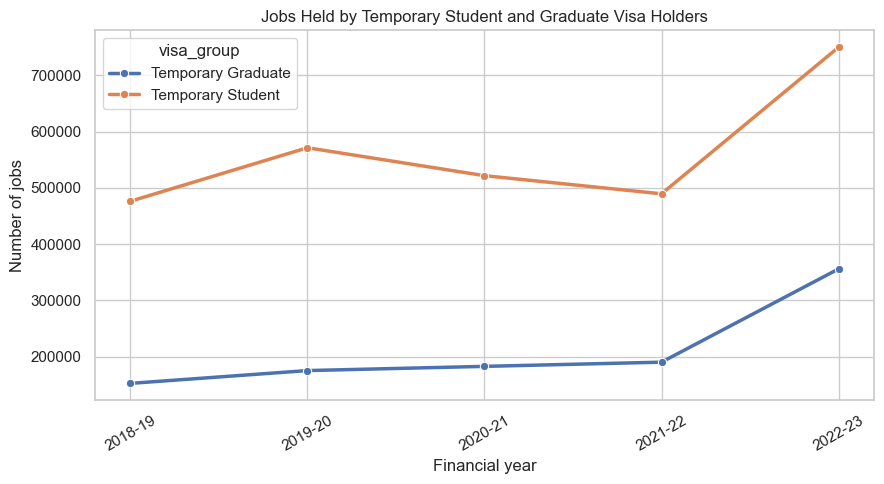

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(9, 5))

sns.lineplot(
    data=comparison_view,
    x="year",
    y="jobs",
    hue="visa_group",
    marker="o",
    linewidth=2.5,
    ax=ax
)

ax.set_title(
    "Jobs Held by Temporary Student and Graduate Visa Holders"
)
ax.set_xlabel("Financial year")
ax.set_ylabel("Number of jobs")
ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()


In [20]:
figure_file = (
    PROJECT_ROOT
    / "outputs"
    / "figures"
    / "national_jobs_trend.png"
)

fig.savefig(
    figure_file,
    dpi=300,
    bbox_inches="tight"
)

print("图片已保存：", figure_file)

图片已保存： /Users/tttonya/PycharmProjects/JupyterProject/outputs/figures/national_jobs_trend.png


In [21]:
from pathlib import Path

# Notebook位于notebooks文件夹，所以项目根目录是上一级
PROJECT_ROOT = Path.cwd().parent

output_file = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "student_employment_panel.csv"
)

# 确保processed文件夹存在
output_file.parent.mkdir(parents=True, exist_ok=True)

# 导出清洗后的完整数据
panel.to_csv(output_file, index=False)

print("保存成功：", output_file)
print("文件是否存在：", output_file.exists())
print("数据行列数：", panel.shape)

保存成功： /Users/tttonya/PycharmProjects/JupyterProject/data/processed/student_employment_panel.csv
文件是否存在： True
数据行列数： (47700, 11)


In [22]:
TABLEAU_DIR = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "tableau"
)

TABLEAU_DIR.mkdir(
    parents=True,
    exist_ok=True
)


In [23]:
national_trend = panel.query(
    "visa_group in ['Temporary Student', 'Temporary Graduate'] and "
    "applicant_status == 'Total' and "
    "sex == 'Persons' and "
    "state == 'Australia' and "
    "industry == 'Total'"
).copy()

national_trend.to_csv(
    TABLEAU_DIR / "national_trend.csv",
    index=False
)

display(national_trend)

,state_code,state,visa_group,applicant_status,industry,sex,has_suppressed_value,has_nil_or_rounded_zero,year,jobs,median_income_per_job
7765,0,Australia,Temporary Graduate,Total,Total,Persons,False,False,2018-19,152465.0,12830.0
7766,0,Australia,Temporary Graduate,Total,Total,Persons,False,False,2019-20,175222.0,13352.0
7767,0,Australia,Temporary Graduate,Total,Total,Persons,False,False,2020-21,182695.0,13114.0
7768,0,Australia,Temporary Graduate,Total,Total,Persons,False,False,2021-22,190162.0,13654.0
7769,0,Australia,Temporary Graduate,Total,Total,Persons,False,False,2022-23,355883.0,15505.0
10465,0,Australia,Temporary Student,Total,Total,Persons,False,False,2018-19,476081.0,6753.0
10466,0,Australia,Temporary Student,Total,Total,Persons,False,False,2019-20,571204.0,7173.0
10467,0,Australia,Temporary Student,Total,Total,Persons,False,False,2020-21,521604.0,8141.0
10468,0,Australia,Temporary Student,Total,Total,Persons,False,False,2021-22,489335.0,6925.0
10469,0,Australia,Temporary Student,Total,Total,Persons,False,False,2022-23,749847.0,6752.0


In [24]:
state_comparison = panel.query(
    "visa_group in ['Temporary Student', 'Temporary Graduate'] and "
    "applicant_status == 'Total' and "
    "sex == 'Persons' and "
    "state != 'Australia' and "
    "industry == 'Total'"
).copy()

state_comparison.to_csv(
    TABLEAU_DIR / "state_comparison.csv",
    index=False
)

display(state_comparison.head())

,state_code,state,visa_group,applicant_status,industry,sex,has_suppressed_value,has_nil_or_rounded_zero,year,jobs,median_income_per_job
14665,1,New South Wales,Temporary Graduate,Total,Total,Persons,False,False,2018-19,50965.0,15047.0
14666,1,New South Wales,Temporary Graduate,Total,Total,Persons,False,False,2019-20,55864.0,16103.0
14667,1,New South Wales,Temporary Graduate,Total,Total,Persons,False,False,2020-21,57647.0,14862.0
14668,1,New South Wales,Temporary Graduate,Total,Total,Persons,False,False,2021-22,53744.0,15360.0
14669,1,New South Wales,Temporary Graduate,Total,Total,Persons,False,False,2022-23,99193.0,17374.0


In [25]:
industry_comparison = panel.query(
    "visa_group in ['Temporary Student', 'Temporary Graduate'] and "
    "applicant_status == 'Total' and "
    "sex == 'Persons' and "
    "state == 'Australia' and "
    "industry != 'Total'"
).copy()

industry_comparison.to_csv(
    TABLEAU_DIR / "industry_comparison.csv",
    index=False
)

display(industry_comparison.head())

,state_code,state,visa_group,applicant_status,industry,sex,has_suppressed_value,has_nil_or_rounded_zero,year,jobs,median_income_per_job
7510,0,Australia,Temporary Graduate,Total,Accommodation and Food Services,Persons,False,False,2018-19,27478.0,10299.0
7511,0,Australia,Temporary Graduate,Total,Accommodation and Food Services,Persons,False,False,2019-20,32616.0,10040.0
7512,0,Australia,Temporary Graduate,Total,Accommodation and Food Services,Persons,False,False,2020-21,32168.0,8978.0
7513,0,Australia,Temporary Graduate,Total,Accommodation and Food Services,Persons,False,False,2021-22,30293.0,9185.0
7514,0,Australia,Temporary Graduate,Total,Accommodation and Food Services,Persons,False,False,2022-23,67325.0,12501.0


In [26]:
for file in TABLEAU_DIR.glob("*.csv"):
    print(file.name)

state_comparison.csv
national_trend.csv
industry_comparison.csv
